In [2]:
!unzip -q "/kaggle/input/competitions/dogs-vs-cats/train.zip" -d /kaggle/working/

In [3]:
import random
import os
random.seed(42)
train_path="/kaggle/working/train"
paths=os.listdir("/kaggle/working/train")
random.shuffle(paths)
cat_paths=[ path for path in paths if path[:3]=="cat"]
dog_paths=[ path for path in paths if path[:3]=="dog"]
len(cat_paths),len(dog_paths)


(12500, 12500)

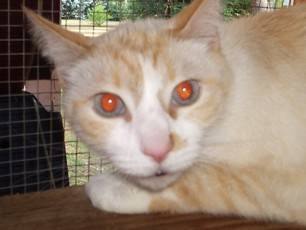

In [29]:
from PIL import Image
img_path=os.path.join(train_path,cat_paths[0])
img=Image.open(img_path)
img


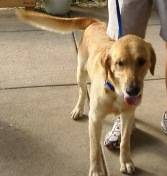

In [4]:
img_path=os.path.join(train_path,dog_paths[0])
Image.open(img_path)

In [4]:
all_paths=cat_paths+dog_paths
random.shuffle(all_paths)
random.shuffle(all_paths)
train_paths=all_paths[5000:]
dev_paths=all_paths[:5000]
len(train_paths),len(dev_paths)

(20000, 5000)

In [6]:
import torch
from torch.utils.data import Dataset,DataLoader
class Data(Dataset):
    def __init__(self,paths,transform):
        self.paths=paths
        self.transform=transform
        
        
    def __len__(self):
        return len(self.paths)
        
    def __getitem__(self,index):
        y=int(self.paths[index][:3]=="cat")
        x=os.path.join(train_path,self.paths[index])
        x=Image.open(x)
        x=x.resize((227,227))
        if self.transform is not None:
            x=self.transform(x)/255.0
              
        return x,y
        
            
        
        
        
        

In [7]:
from torchvision import transforms
transform=transforms.Compose([
    transforms.PILToTensor()
])

In [8]:
train_data=Data(train_paths,transform)
dev_data=Data(dev_paths,transform)

In [9]:
batch_size=64
train_loader=DataLoader(train_data,batch_size=batch_size,shuffle=True)
dev_loader=DataLoader(dev_data,batch_size=batch_size,shuffle=True)

In [10]:
next(iter(train_loader))

[tensor([[[[0.2745, 0.2471, 0.2118,  ..., 0.4431, 0.4118, 0.4157],
           [0.2863, 0.2863, 0.2431,  ..., 0.4588, 0.4314, 0.3882],
           [0.2078, 0.2824, 0.2784,  ..., 0.4706, 0.4471, 0.3490],
           ...,
           [0.7647, 0.7333, 0.7373,  ..., 0.7333, 0.7529, 0.7804],
           [0.7843, 0.7451, 0.7333,  ..., 0.7216, 0.7294, 0.7490],
           [0.7647, 0.7451, 0.7412,  ..., 0.7294, 0.7255, 0.7333]],
 
          [[0.2745, 0.2471, 0.2118,  ..., 0.4745, 0.4471, 0.4588],
           [0.2863, 0.2863, 0.2431,  ..., 0.4941, 0.4706, 0.4314],
           [0.2078, 0.2824, 0.2784,  ..., 0.5020, 0.4863, 0.3843],
           ...,
           [0.7137, 0.6824, 0.6863,  ..., 0.7020, 0.7176, 0.7451],
           [0.7333, 0.6941, 0.6824,  ..., 0.6902, 0.6941, 0.7137],
           [0.7137, 0.6941, 0.6902,  ..., 0.6941, 0.6902, 0.6980]],
 
          [[0.2431, 0.2157, 0.1804,  ..., 0.5098, 0.4863, 0.4980],
           [0.2549, 0.2549, 0.2118,  ..., 0.5255, 0.5059, 0.4667],
           [0.1765, 0.25

In [11]:
next(iter(dev_loader))

[tensor([[[[0.4353, 0.5725, 0.4392,  ..., 0.5412, 0.5294, 0.5490],
           [0.5647, 0.5922, 0.5020,  ..., 0.5529, 0.5294, 0.5412],
           [0.5294, 0.4980, 0.6471,  ..., 0.5373, 0.5255, 0.5412],
           ...,
           [0.4627, 0.4392, 0.4392,  ..., 0.4667, 0.4824, 0.5020],
           [0.4745, 0.4510, 0.4314,  ..., 0.4314, 0.4471, 0.4549],
           [0.4902, 0.4667, 0.4196,  ..., 0.5098, 0.5137, 0.5216]],
 
          [[0.5176, 0.6627, 0.5412,  ..., 0.4980, 0.4902, 0.5137],
           [0.6471, 0.6824, 0.6000,  ..., 0.5059, 0.4902, 0.5098],
           [0.6157, 0.5804, 0.7490,  ..., 0.4980, 0.4863, 0.5059],
           ...,
           [0.3882, 0.3647, 0.3647,  ..., 0.4588, 0.4706, 0.4824],
           [0.4000, 0.3765, 0.3569,  ..., 0.4235, 0.4353, 0.4392],
           [0.4157, 0.3922, 0.3451,  ..., 0.5020, 0.5020, 0.5059]],
 
          [[0.4980, 0.6667, 0.5843,  ..., 0.4745, 0.4667, 0.4941],
           [0.6314, 0.6863, 0.6471,  ..., 0.4824, 0.4667, 0.4902],
           [0.6039, 0.59

In [20]:
import torch.nn as  nn
import torch
class myAlexNet(nn.Module):
    def _init_parameters(self):
        for m in self.modules():
            if isinstance(m,nn.Linear):
                nn.init.kaiming_normal_(m.weight, nonlinearity="relu")
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
                
            
                
    def __init__(self,n_classes,p=0.2):
        super().__init__()
        self.Conv1=nn.Conv2d(3,96,stride=4,kernel_size=(11,11))
        self.MaxPool1=nn.MaxPool2d(stride=2,kernel_size=(3,3))
        self.Conv2=nn.Conv2d(96,256,stride=1,kernel_size=(5,5),padding="same")
        self.MaxPool2=nn.MaxPool2d(stride=2,kernel_size=(3,3))
        self.Conv3=nn.Conv2d(256,384,stride=1,kernel_size=(3,3),padding="same")
        self.Conv4=nn.Conv2d(384,384,stride=1,kernel_size=(3,3),padding="same")
        self.Conv5=nn.Conv2d(384,256,stride=1,kernel_size=(3,3),padding="same")
        self.MaxPool5=nn.MaxPool2d(stride=2,kernel_size=(3,3))
        self.FC1=nn.Linear(9216,4096)
        self.FC2=nn.Linear(4096,4096)
        self.FC3=nn.Linear(4096,1000)
        self.FC4=nn.Linear(1000,100)
        self.FC5=nn.Linear(100,10)
        self.FC6=nn.Linear(10,n_classes)
        self.dropout=nn.Dropout(p=p)
        self._init_parameters()
    def forward(self,x) :
         x=torch.relu(self.Conv1(x))
         x=self.MaxPool1(x)
         x=torch.relu(self.Conv2(x))
         x=self.MaxPool2(x)
         x=torch.relu(self.Conv3(x))
         x=torch.relu(self.Conv4(x))
         x=torch.relu(self.Conv5(x))
         x=self.MaxPool5(x)
         x=x.flatten(1)
         x=self.dropout(torch.relu(self.FC1(x)))
         x=self.dropout(torch.relu(self.FC2(x)))
         x=self.dropout(torch.relu(self.FC3(x)))
         x=self.dropout(torch.relu(self.FC4(x)))
         x=torch.relu(self.FC5(x))
         x=self.FC6(x)
         return x
         
         
        
        
        
        
        
        
    


In [17]:
model=myAlexNet(2,0.3)
criterion = nn.CrossEntropyLoss()


In [18]:
optim=torch.optim.Adam(model.parameters(),lr=0.0001)

In [21]:
device=("cuda" if torch.cuda.is_available() else "cpu")
def train_Model(model,criterion,optim,train_loader,test_loader,n_epochs): 
    model.to(device)
    Train_loss_buffer=[]
    Test_loss_buffer=[]
    for epoch in range(n_epochs):
        train_loss=0
        correct_train_predictions=0
        n_train_samples=0
        model.train(True)
        for batch,(X,Y)in enumerate(train_loader):
            X=X.to(device)
            Y=Y.to(device)
            train_predictions=model(X)
            loss=criterion(train_predictions,Y)
            train_loss+=loss.item()
            optim.zero_grad()
            loss.backward()
            optim.step()
            train_predictions=torch.argmax(train_predictions,dim=1)
            correct_train_predictions+=(train_predictions==Y).sum().item()
            n_train_samples+=len(Y)
            if (batch%50==0):
                print(f"Epoch {epoch+1}: Batch {batch}/{len(train_loader)} | Loss {loss.item():.4f}")
        Average_train_Loss= train_loss/  len(train_loader)
        training_acc=correct_train_predictions/n_train_samples
        Train_loss_buffer.append(Average_train_Loss)
        test_loss=0
        correct_test_predictions=0
        n_test_samples=0
        model.eval()
        with torch.no_grad():
            for batch,(X,Y)in enumerate(test_loader):
                X=X.to(device)
                Y=Y.to(device)
                test_predictions=model(X)
                loss=criterion(test_predictions,Y)
                test_loss+=loss.item()
                test_predictions=torch.argmax(test_predictions,dim=1)
                correct_test_predictions+=(test_predictions==Y).sum().item()
                n_test_samples+=len(Y)
        Average_test_Loss= test_loss/  len(test_loader)
        testing_acc=correct_test_predictions/n_test_samples
        Test_loss_buffer.append(Average_test_Loss)
        print(f"Epoch {epoch+1}/{n_epochs} | "
              f"train loss {Average_train_Loss:.4f} acc {training_acc*100:.3f} | "
              f"test loss {Average_test_Loss:.4f} acc {testing_acc*100:.3f}")
            
            
    return Train_loss_buffer,Test_loss_buffer       
                
            
        
        
        
            
            
            
            
            
            
        

In [20]:
Train_losses,Test_loss_buffer=train_Model(model,criterion,optim,train_loader,dev_loader,10)

Epoch 1: Batch 0/313 | Loss 0.6945
Epoch 1: Batch 50/313 | Loss 0.6921
Epoch 1: Batch 100/313 | Loss 0.7197
Epoch 1: Batch 150/313 | Loss 0.6831
Epoch 1: Batch 200/313 | Loss 0.6491
Epoch 1: Batch 250/313 | Loss 0.5987
Epoch 1: Batch 300/313 | Loss 0.5979
Epoch 1/10 | train loss 0.6707 acc 57.785 | test loss 0.6190 acc 66.340
Epoch 2: Batch 0/313 | Loss 0.6022
Epoch 2: Batch 50/313 | Loss 0.7351
Epoch 2: Batch 100/313 | Loss 0.6629
Epoch 2: Batch 150/313 | Loss 0.6602
Epoch 2: Batch 200/313 | Loss 0.4317
Epoch 2: Batch 250/313 | Loss 0.6369
Epoch 2: Batch 300/313 | Loss 0.5621
Epoch 2/10 | train loss 0.5933 acc 68.210 | test loss 0.5245 acc 73.560
Epoch 3: Batch 0/313 | Loss 0.5307
Epoch 3: Batch 50/313 | Loss 0.4629
Epoch 3: Batch 100/313 | Loss 0.4224
Epoch 3: Batch 150/313 | Loss 0.7037
Epoch 3: Batch 200/313 | Loss 0.4169
Epoch 3: Batch 250/313 | Loss 0.4529
Epoch 3: Batch 300/313 | Loss 0.5904
Epoch 3/10 | train loss 0.4851 acc 76.480 | test loss 0.4221 acc 79.940
Epoch 4: Batch 0

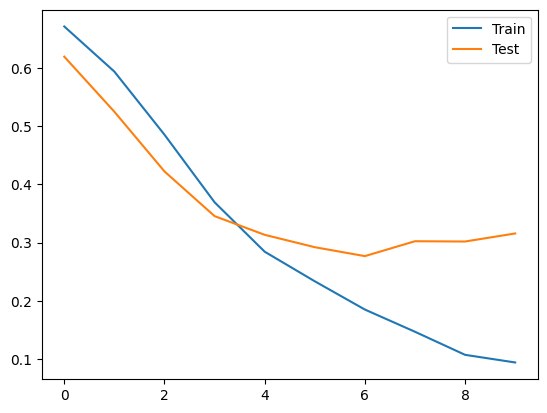

In [24]:
import matplotlib.pyplot as plt
plt.plot(Train_losses,label="Train")
plt.plot(Test_loss_buffer,label="Test")
plt.legend()
plt.show()

# Data augmentation

In [13]:
import torch
from torch.utils.data import Dataset,DataLoader
class Data(Dataset):
    def __init__(self,paths,transform):
        self.paths=paths
        self.transform=transform
        
        
    def __len__(self):
        return len(self.paths)
        
    def __getitem__(self,index):
        y=int(self.paths[index][:3]=="cat")
        x=os.path.join(train_path,self.paths[index])
        x=Image.open(x)
        x=x.resize((227,227))
        if self.transform is not None:
            x=self.transform(x)
              
        return x,y
        
            
        
        
        
        

In [14]:
from torchvision.transforms import v2
train_transform=v2.Compose([
    v2.PILToTensor(),
    v2.RandomHorizontalFlip(p=0.5),
    v2.RandomResizedCrop(size=(227,227),antialias=True),
    v2.ToDtype(torch.float32, scale=True) 
])

In [15]:

dev_transform=v2.Compose([
    v2.PILToTensor(),
    v2.ToDtype(torch.float32, scale=True) 
])

In [24]:
train_data=Data(train_paths,train_transform)
dev_data=Data(dev_paths,dev_transform)

In [25]:
batch_size=64
train_loader=DataLoader(train_data,batch_size=batch_size,shuffle=True)
dev_loader=DataLoader(dev_data,batch_size=batch_size,shuffle=True)

In [31]:
model=myAlexNet(2,0)
criterion = nn.CrossEntropyLoss()

In [32]:
optim=torch.optim.Adam(model.parameters(),lr=0.0001)

In [33]:
Train_losses,Test_losses=train_Model(model,criterion,optim,train_loader,dev_loader,10)

Epoch 1: Batch 0/313 | Loss 0.6939
Epoch 1: Batch 50/313 | Loss 0.6929
Epoch 1: Batch 100/313 | Loss 0.6930
Epoch 1: Batch 150/313 | Loss 0.6932
Epoch 1: Batch 200/313 | Loss 0.6901
Epoch 1: Batch 250/313 | Loss 0.7093
Epoch 1: Batch 300/313 | Loss 0.6808
Epoch 1/10 | train loss 0.6903 acc 52.645 | test loss 0.6709 acc 58.780
Epoch 2: Batch 0/313 | Loss 0.7221
Epoch 2: Batch 50/313 | Loss 0.7025
Epoch 2: Batch 100/313 | Loss 0.6421
Epoch 2: Batch 150/313 | Loss 0.6793
Epoch 2: Batch 200/313 | Loss 0.6648
Epoch 2: Batch 250/313 | Loss 0.6515
Epoch 2: Batch 300/313 | Loss 0.6539
Epoch 2/10 | train loss 0.6665 acc 59.460 | test loss 0.6382 acc 63.420
Epoch 3: Batch 0/313 | Loss 0.6308
Epoch 3: Batch 50/313 | Loss 0.6820
Epoch 3: Batch 100/313 | Loss 0.6119
Epoch 3: Batch 150/313 | Loss 0.7042
Epoch 3: Batch 200/313 | Loss 0.6377
Epoch 3: Batch 250/313 | Loss 0.6275
Epoch 3: Batch 300/313 | Loss 0.6143
Epoch 3/10 | train loss 0.6360 acc 63.720 | test loss 0.5874 acc 69.480
Epoch 4: Batch 0

In [36]:
# decrease the lr
optim=torch.optim.Adam(model.parameters(),lr=0.00001)

In [37]:
Train_losses,Test_losses=train_Model(model,criterion,optim,train_loader,dev_loader,10)

Epoch 1: Batch 0/313 | Loss 0.5215
Epoch 1: Batch 50/313 | Loss 0.2329
Epoch 1: Batch 100/313 | Loss 0.3341
Epoch 1: Batch 150/313 | Loss 0.2710
Epoch 1: Batch 200/313 | Loss 0.2331
Epoch 1: Batch 250/313 | Loss 0.3126
Epoch 1: Batch 300/313 | Loss 0.3989
Epoch 1/10 | train loss 0.3130 acc 85.540 | test loss 0.2513 acc 89.340
Epoch 2: Batch 0/313 | Loss 0.2651
Epoch 2: Batch 50/313 | Loss 0.2431
Epoch 2: Batch 100/313 | Loss 0.2695
Epoch 2: Batch 150/313 | Loss 0.2664
Epoch 2: Batch 200/313 | Loss 0.3255
Epoch 2: Batch 250/313 | Loss 0.4272
Epoch 2: Batch 300/313 | Loss 0.3378
Epoch 2/10 | train loss 0.2985 acc 86.230 | test loss 0.2554 acc 89.260
Epoch 3: Batch 0/313 | Loss 0.3688
Epoch 3: Batch 50/313 | Loss 0.4622
Epoch 3: Batch 100/313 | Loss 0.3279
Epoch 3: Batch 150/313 | Loss 0.2053
Epoch 3: Batch 200/313 | Loss 0.2982
Epoch 3: Batch 250/313 | Loss 0.3817
Epoch 3: Batch 300/313 | Loss 0.2431
Epoch 3/10 | train loss 0.2876 acc 86.510 | test loss 0.2609 acc 88.600
Epoch 4: Batch 0

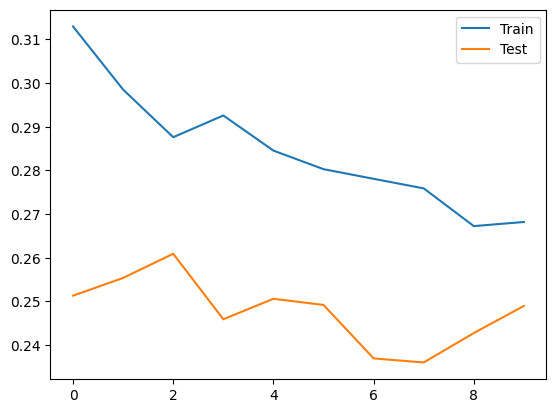

In [38]:
import matplotlib.pyplot as plt
plt.plot(Train_losses,label="Train")
plt.plot(Test_losses,label="Test")
plt.legend()
plt.show()

# Transfer learning with Resnet

In [71]:
from torchvision import models
model=models.resnet50(weights=models.ResNet50_Weights.DEFAULT)

In [72]:
for parameter in model.parameters():
    parameter.requires_grad = False

In [73]:
model

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

In [74]:
model.fc=nn.Sequential(
    nn.Dropout(p=0.3),
    nn.Linear(in_features=2048, out_features=2)
)


In [75]:
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]
train_transform=v2.Compose([
    v2.PILToTensor(),
    v2.RandomHorizontalFlip(p=0.5),
    v2.RandomResizedCrop(size=(227,227),antialias=True),
    v2.ToDtype(torch.float32, scale=True) ,
     v2.Normalize(mean=mean, std=std)
    
])

dev_transform=v2.Compose([
    v2.PILToTensor(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=mean, std=std)
])

In [76]:
train_data=Data(train_paths,train_transform)
dev_data=Data(dev_paths,dev_transform)

In [77]:
batch_size=64
train_loader=DataLoader(train_data,batch_size=batch_size,shuffle=True)
dev_loader=DataLoader(dev_data,batch_size=batch_size,shuffle=True)

In [78]:
optim = torch.optim.Adam(
    [p for p in model.parameters() if p.requires_grad],
    lr=1e-4,
)

In [79]:
Train_losses,Test_losses=train_Model(model,criterion,optim,train_loader,dev_loader,10)

Epoch 1: Batch 0/313 | Loss 0.6621
Epoch 1: Batch 50/313 | Loss 0.5716
Epoch 1: Batch 100/313 | Loss 0.4453
Epoch 1: Batch 150/313 | Loss 0.4162
Epoch 1: Batch 200/313 | Loss 0.4332
Epoch 1: Batch 250/313 | Loss 0.3586
Epoch 1: Batch 300/313 | Loss 0.2912
Epoch 1/10 | train loss 0.4352 acc 87.465 | test loss 0.2377 acc 96.880
Epoch 2: Batch 0/313 | Loss 0.3254
Epoch 2: Batch 50/313 | Loss 0.2805
Epoch 2: Batch 100/313 | Loss 0.2370
Epoch 2: Batch 150/313 | Loss 0.2393
Epoch 2: Batch 200/313 | Loss 0.2284
Epoch 2: Batch 250/313 | Loss 0.2436
Epoch 2: Batch 300/313 | Loss 0.2451
Epoch 2/10 | train loss 0.2636 acc 92.570 | test loss 0.1518 acc 97.460
Epoch 3: Batch 0/313 | Loss 0.2228
Epoch 3: Batch 50/313 | Loss 0.2186
Epoch 3: Batch 100/313 | Loss 0.2055
Epoch 3: Batch 150/313 | Loss 0.2209
Epoch 3/10 | train loss 0.2079 acc 93.505 | test loss 0.1200 acc 97.720
Epoch 4: Batch 0/313 | Loss 0.1660
Epoch 4: Batch 50/313 | Loss 0.1834
Epoch 4: Batch 100/313 | Loss 0.1882
Epoch 4: Batch 150/

In [95]:
for parameter in model.layer4.parameters():
     parameter.requires_grad = False

In [96]:
optim = torch.optim.Adam([
    {"params":model.layer4.parameters(),"lr":1e-5},
    {"params":model.fc.parameters(),"lr":1e-4}]
)

In [98]:
Train_losses,Test_losses=train_Model(model,criterion,optim,train_loader,dev_loader,10)

Epoch 1: Batch 0/313 | Loss 0.1952
Epoch 1: Batch 50/313 | Loss 0.1558
Epoch 1: Batch 100/313 | Loss 0.1012
Epoch 1: Batch 150/313 | Loss 0.1244
Epoch 1: Batch 200/313 | Loss 0.1558
Epoch 1: Batch 250/313 | Loss 0.0842
Epoch 1: Batch 300/313 | Loss 0.1204
Epoch 1/10 | train loss 0.1313 acc 94.790 | test loss 0.0560 acc 98.580
Epoch 2: Batch 0/313 | Loss 0.1390
Epoch 2: Batch 50/313 | Loss 0.1340
Epoch 2: Batch 100/313 | Loss 0.1509
Epoch 2: Batch 150/313 | Loss 0.1049
Epoch 2: Batch 200/313 | Loss 0.0914
Epoch 2: Batch 250/313 | Loss 0.1721
Epoch 2: Batch 300/313 | Loss 0.2140
Epoch 2/10 | train loss 0.1307 acc 94.735 | test loss 0.0535 acc 98.540
Epoch 3: Batch 0/313 | Loss 0.0732
Epoch 3: Batch 50/313 | Loss 0.0996
Epoch 3: Batch 100/313 | Loss 0.1549
Epoch 3: Batch 150/313 | Loss 0.1625
Epoch 3: Batch 200/313 | Loss 0.1815
Epoch 3: Batch 250/313 | Loss 0.0537
Epoch 3: Batch 300/313 | Loss 0.1142
Epoch 3/10 | train loss 0.1325 acc 94.465 | test loss 0.0501 acc 98.560
Epoch 4: Batch 0